#first generate dataset2_normal_then_control_meet_at_least_one_condition.csv, all sequences

In [2]:
import numpy as np
import pandas as pd
import os


In [3]:
# initialize dataFrames
def initialize_dfs(names):
    return {name: pd.DataFrame() for name in names}
    
# function to read csv files into dataframes
def read_csv_files(names, df_dict, base_path, columns):
    for name in names:
        file_path = os.path.join(base_path, name, "produce_final_form/final_form.csv")
        df_dict[name] = pd.read_csv(file_path, sep=',', usecols=columns)

# Filter conditions: mirBase, linearfold, mirdeep2
def filter_dataframes(names, df_source, df_with_match):
    for name in names:
        df_with_match[name] = filter_any_condition_met(df_source[name])
        # df_all_zero[name] = filter_none_met(df_source[name])

def filter_any_condition_met(df):
    filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) > 0)]
    #filtered_df = filtered_df.loc[:, ['sequence']]
    filtered_df = filtered_df.loc[:, ['sequence', 'qseqid_count']]
    # print("filtered_df",filtered_df)
    return filtered_df

# def filter_none_met(df):
#     filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) == 0)]
#     filtered_df = filtered_df.loc[:, ['sequence']]
#     # filtered_df = filtered_df.loc[:, ['sequence', 'umi_count']]
#     # print("filtered_df_none",filtered_df)
#     return filtered_df

def merge_seqid_count(df, result_df, column_name):
    result_df = result_df.merge(df, on='sequence', how='left').fillna(0)
    result_df = result_df.rename(columns={'qseqid_count': column_name})
    return result_df

# function to generate form and save the result
def generate_and_save_result(names, df_dict, output_file):
    all_sequences = pd.concat([df_dict[name]['sequence'] for name in names]).unique()
    result_df = pd.DataFrame({'sequence': all_sequences})
    
    for name in names:
        df = df_dict[name]
        result_df = merge_seqid_count(df, result_df, f'{name}')
    print("result_df",result_df)
    result_df.to_csv(os.path.join(base_path, output_file), index=False)

In [4]:
# define the base path for output csv files
base_path = "../../../../2nd_6samples_output"

# names corresponding to the file names for normal and control
#first three is total group, second line is control group
total_names = [
    "SRR18078869", "SRR18078868", "SRR18078867",
    "SRR18078872", "SRR18078871", "SRR18078870"
]

# columns to read from the original CSV files
read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']


df_total = initialize_dfs(total_names)
df_total_with_match = initialize_dfs(total_names)


read_csv_files(total_names, df_total, base_path, read_columns)


filter_dataframes(total_names, df_total, df_total_with_match)
for name in total_names:
    num_rows = len(df_total_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")

print(df_total_with_match)


generate_and_save_result(total_names, df_total_with_match, "dataset2_DSS_then_control_meet_at_least_one_condition_all_seuquences.csv")


DataFrame SRR18078869 has 38450 lines.
DataFrame SRR18078868 has 49594 lines.
DataFrame SRR18078867 has 73721 lines.
DataFrame SRR18078872 has 50518 lines.
DataFrame SRR18078871 has 38747 lines.
DataFrame SRR18078870 has 72808 lines.
{'SRR18078869':                        sequence  qseqid_count
0          CCCACCCCCCGTCGCCTCCG           464
1           GGAGAAGCCGGCGGGAGCC         62586
2      CGGAGAAGCCGGCGGGAGCCCCGG         38168
3        TCCCGCCGTCGCCGTCCCCGCT           813
4           GCACCCGTAGCTCAGCTGG           351
...                         ...           ...
46018   AGGGAACGGGCTTGGCGGAATCA             1
46019      AGAGTTTGATCCTGGCTCAG             2
46020    CCGGTCGGGGGACGGATTGGGA             1
46021     CGAACGAGACTCTGGCATGCT             1
46022     CAACCGAGATTCCCCCAGTAG             1

[38450 rows x 2 columns], 'SRR18078868':                                  sequence  qseqid_count
0               CACTGACTGGAGGACCGAACCGACT             1
1      GCGTGAGTGAAGAAGGCCTTCGGGTTGTAAAGCT   

         index   0     1     2   3  4   5   6     7   8  ...  186567  186568  \
0  SRR18078869  12  1737  1059  22  9  57  17  5451   7  ...       0       0   
1  SRR18078868   6    37    81  24  1   2  16   278  12  ...       0       0   
2  SRR18078867   5    79    48   0  0   0  12   516   0  ...       0       0   
3  SRR18078872   0     0     1   0  0   0   0     1   0  ...       0       0   
4  SRR18078871   0     1     2   0  0   0   0     0   0  ...       0       0   
5  SRR18078870   0     1     8   0  0   0   0     3   0  ...       0       0   

   186569  186570  186571  186572  186573  186574  186575  186576  
0       0       0       0       0       0       0       0       0  
1       0       0       0       0       0       0       0       0  
2       0       0       0       0       0       0       0       0  
3       0       0       0       0       0       0       0       0  
4       0       0       0       0       0       0       0       0  
5       0       0       0      

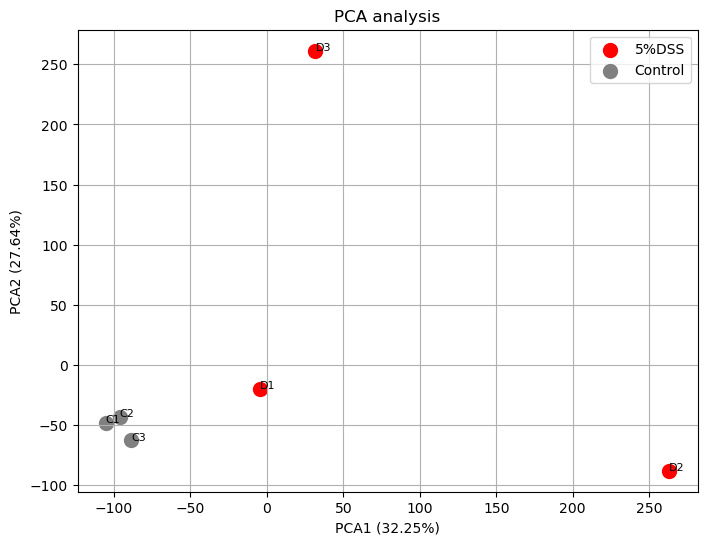

In [5]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import os
import pandas as pd
import glob

base_path = "../../../../2nd_6samples_output"
total_df = pd.read_csv(os.path.join(base_path, "dataset2_DSS_then_control_meet_at_least_one_condition_all_seuquences.csv"), sep=",")
total = total_df.drop('sequence', axis=1)
# print(total.head())
### totalize
total_totalized = total.div(total.sum())
#print(total_totalized.head())
total_totalized = total_totalized.mul(10**5).astype(int)

matrix_transpose_total = total_totalized.T.reset_index()
y_total = matrix_transpose_total['index'].to_list()
print(matrix_transpose_total)
# print(y_total)


X = matrix_transpose_total.drop(columns='index').to_numpy()
print(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled)
print("Mean after standardization:", X_scaled.mean(axis=0))
print("Std dev after standardization:", X_scaled.std(axis=0))
stds = X_scaled.std(axis=0)
print("Standard Deviations:", stds)
zero_var_features = np.where(stds == 0)[0]
print("Features with zero variance:", zero_var_features)
data_reduced = np.delete(X_scaled, zero_var_features, axis=1)
print("Std dev after filter 0 standardization:", data_reduced.std(axis=0))



pca = PCA(n_components=2)
X_pca = pca.fit_transform(data_reduced)

pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
print(pca_df)

pca_df['Sample'] = ['D1', 'D2', 'D3','C1','C2','C3']
# pca_df['Sample'] = y_total
print(y_total)
pca_df['Group'] = ['5%DSS','5%DSS','5%DSS','Control','Control','Control']

plt.figure(figsize=(8, 6))
colors = {'5%DSS': 'red', 'Control': 'gray'}

for group in pca_df['Group'].unique():
    subset = pca_df[pca_df['Group'] == group]
    plt.scatter(subset['PC1'], subset['PC2'], label=group, color=colors[group], s=100)

for i, row in pca_df.iterrows():
    plt.text(row['PC1'], row['PC2'], row['Sample'],fontsize=8) 

plt.title('PCA analysis')
# plt.xlabel('PCA 1')
# plt.ylabel('PCA 2')
plt.xlabel(f'PCA1 ({pca.explained_variance_ratio_[0]*100:.2f}%)')
plt.ylabel(f'PCA2 ({pca.explained_variance_ratio_[1]*100:.2f}%)')
plt.legend()
plt.grid(True)
plt.show()


at least 2 samples shared sequences

In [6]:
import numpy as np
import pandas as pd
import os
# initialize dataFrames
def initialize_dfs(names):
    return {name: pd.DataFrame() for name in names}
    
# function to read csv files into dataframes
def read_csv_files(names, df_dict, base_path, columns):
    for name in names:
        file_path = os.path.join(base_path, name, "produce_final_form/final_form.csv")
        df_dict[name] = pd.read_csv(file_path, sep=',', usecols=columns)

# Filter conditions: mirBase, linearfold, mirdeep2
def filter_dataframes(names, df_source, df_with_match):
    for name in names:
        df_with_match[name] = filter_any_condition_met(df_source[name])
        # df_all_zero[name] = filter_none_met(df_source[name])

def filter_any_condition_met(df):
    filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) > 0)]
    #filtered_df = filtered_df.loc[:, ['sequence']]
    filtered_df = filtered_df.loc[:, ['sequence', 'qseqid_count']]
    # print("filtered_df",filtered_df)
    return filtered_df

# def filter_none_met(df):
#     filtered_df = df[(df[['mirBase', 'linearfold', 'mirdeep2']].sum(axis=1) == 0)]
#     filtered_df = filtered_df.loc[:, ['sequence']]
#     # filtered_df = filtered_df.loc[:, ['sequence', 'umi_count']]
#     # print("filtered_df_none",filtered_df)
#     return filtered_df

def merge_seqid_count(df, result_df, column_name):
    result_df = result_df.merge(df, on='sequence', how='left').fillna(0)
    result_df = result_df.rename(columns={'qseqid_count': column_name})
    return result_df

# function to generate form and save the result
def generate_and_save_result(names, df_dict, output_file):
    all_sequences = pd.concat([df_dict[name]['sequence'] for name in names]).unique()
    result_df = pd.DataFrame({'sequence': all_sequences})
    
    for name in names:
        df = df_dict[name]
        result_df = merge_seqid_count(df, result_df, f'{name}')
    print("result_df",result_df.head(5))
    # Select only SRR columns
    srr_cols = [col for col in result_df.columns if col.startswith('SRR')]

    # Keep rows where exactly one SRR column is > 0
    final_df = result_df[(result_df[srr_cols] > 0).sum(axis=1) > 1]
    final_df.to_csv(os.path.join(base_path, output_file), index=False)


# define the base path for output csv files
base_path = "../../../../2nd_6samples_output"

# names corresponding to the file names for normal and control
#first three is total group, second line is control group
total_names = [
    "SRR18078869", "SRR18078868", "SRR18078867",
    "SRR18078872", "SRR18078871", "SRR18078870"
]

# columns to read from the original CSV files
read_columns = ['sequence', 'mirBase', 'linearfold', 'mirdeep2','qseqid_count']


df_total = initialize_dfs(total_names)
df_total_with_match = initialize_dfs(total_names)


read_csv_files(total_names, df_total, base_path, read_columns)


filter_dataframes(total_names, df_total, df_total_with_match)
for name in total_names:
    num_rows = len(df_total_with_match[name])
    print(f"DataFrame {name} has {num_rows} lines.")

print(df_total_with_match)


generate_and_save_result(total_names, df_total_with_match, "dataset2_DSS_then_control_meet_at_least_one_condition_common_sequences.csv")

DataFrame SRR18078869 has 38450 lines.
DataFrame SRR18078868 has 49594 lines.
DataFrame SRR18078867 has 73721 lines.
DataFrame SRR18078872 has 50518 lines.
DataFrame SRR18078871 has 38747 lines.
DataFrame SRR18078870 has 72808 lines.
{'SRR18078869':                        sequence  qseqid_count
0          CCCACCCCCCGTCGCCTCCG           464
1           GGAGAAGCCGGCGGGAGCC         62586
2      CGGAGAAGCCGGCGGGAGCCCCGG         38168
3        TCCCGCCGTCGCCGTCCCCGCT           813
4           GCACCCGTAGCTCAGCTGG           351
...                         ...           ...
46018   AGGGAACGGGCTTGGCGGAATCA             1
46019      AGAGTTTGATCCTGGCTCAG             2
46020    CCGGTCGGGGGACGGATTGGGA             1
46021     CGAACGAGACTCTGGCATGCT             1
46022     CAACCGAGATTCCCCCAGTAG             1

[38450 rows x 2 columns], 'SRR18078868':                                  sequence  qseqid_count
0               CACTGACTGGAGGACCGAACCGACT             1
1      GCGTGAGTGAAGAAGGCCTTCGGGTTGTAAAGCT   

In [7]:
#then use above two files to generate PCA figure.

In [8]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import os
import pandas as pd
import glob

In [9]:
base_path = "../../../../2nd_6samples_output"

In [10]:

total_df = pd.read_csv(os.path.join(base_path, "dataset2_DSS_then_control_meet_at_least_one_condition_common_sequences.csv"), sep=",")
# control_df = pd.read_csv(os.path.join(base_path, "dataset2_control_meet_at_least_one_condition.csv"), sep=",")

In [11]:
total = total_df.drop('sequence', axis=1)
# print(total.head())
### totalize
total_totalized = total.div(total.sum())
#print(total_totalized.head())
total_totalized = total_totalized.mul(10**5).astype(int)

matrix_transpose_total = total_totalized.T.reset_index()
y_total = matrix_transpose_total['index'].to_list()
print(matrix_transpose_total)
# print(y_total)

         index   0     1     2   3   4   5   6     7   8  ...  76233  76234  \
0  SRR18078869  13  1835  1119  23  10  60  18  5760   7  ...      0      0   
1  SRR18078868   7    41    90  26   1   2  18   307  13  ...      0      0   
2  SRR18078867   8   120    73   0   0   0  18   779   0  ...      0      0   
3  SRR18078872   0     0     1   0   0   0   0     2   0  ...      0      0   
4  SRR18078871   0     1     2   0   0   0   0     0   0  ...      0      0   
5  SRR18078870   0     1     9   0   0   0   0     3   0  ...      0      0   

   76235  76236  76237  76238  76239  76240  76241  76242  
0      0      0      0      0      0      0      0      0  
1      0      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0      0  
3      0      0      0      0      0      0      0      0  
4      0      0      0      0      0      0      0      0  
5      0      0      0      0      0      0      0      0  

[6 rows x 76244 columns]


[[  13 1835 1119 ...    0    0    0]
 [   7   41   90 ...    0    0    0]
 [   8  120   73 ...    0    0    0]
 [   0    0    1 ...    0    0    0]
 [   0    1    2 ...    0    0    0]
 [   0    1    9 ...    0    0    0]]
[[ 1.65930828  2.23163369  2.22767778 ...  0.          0.
   0.        ]
 [ 0.46460632 -0.43384623 -0.30990204 ...  0.          0.
   0.        ]
 [ 0.66372331 -0.31647002 -0.35182512 ...  0.          0.
   0.        ]
 [-0.92921264 -0.49476299 -0.52938173 ...  0.          0.
   0.        ]
 [-0.92921264 -0.49327722 -0.52691567 ...  0.          0.
   0.        ]
 [-0.92921264 -0.49327722 -0.50965322 ...  0.          0.
   0.        ]]
Mean after standardization: [-1.48029737e-16 -5.55111512e-17  0.00000000e+00 ...  0.00000000e+00
  0.00000000e+00  0.00000000e+00]
Std dev after standardization: [1. 1. 1. ... 0. 0. 0.]
Standard Deviations: [1. 1. 1. ... 0. 0. 0.]
Features with zero variance: [   14    88   106 ... 76240 76241 76242]
Std dev after filter 0 standardizati

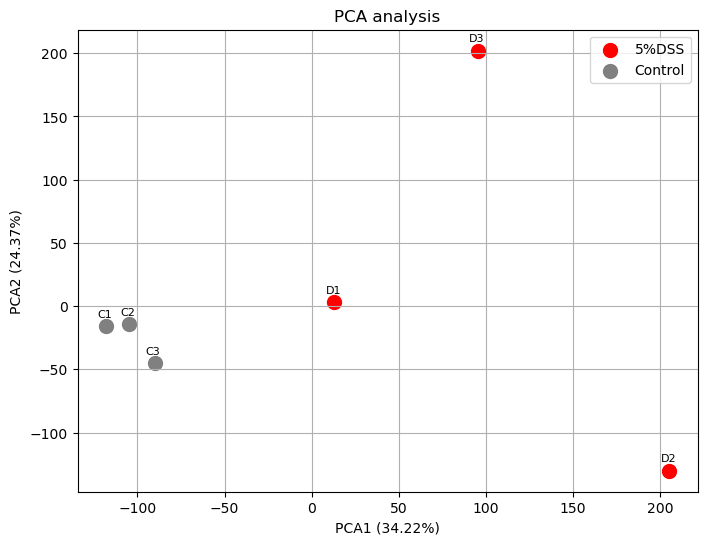

In [12]:

X = matrix_transpose_total.drop(columns='index').to_numpy()
print(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled)
print("Mean after standardization:", X_scaled.mean(axis=0))
print("Std dev after standardization:", X_scaled.std(axis=0))
stds = X_scaled.std(axis=0)
print("Standard Deviations:", stds)
zero_var_features = np.where(stds == 0)[0]
print("Features with zero variance:", zero_var_features)
data_reduced = np.delete(X_scaled, zero_var_features, axis=1)
print("Std dev after filter 0 standardization:", data_reduced.std(axis=0))


pca = PCA(n_components=2)
X_pca = pca.fit_transform(data_reduced)

pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
print(pca_df)

pca_df['Sample'] = ['D1', 'D2', 'D3','C1','C2','C3']
# pca_df['Sample'] = y_total
print(y_total)
pca_df['Group'] = ['5%DSS','5%DSS','5%DSS','Control','Control','Control']

plt.figure(figsize=(8, 6))
colors = {'5%DSS': 'red', 'Control': 'gray'}

for group in pca_df['Group'].unique():
    subset = pca_df[pca_df['Group'] == group]
    plt.scatter(subset['PC1'], subset['PC2'], label=group, color=colors[group], s=100)

for i, row in pca_df.iterrows():
    plt.text(row['PC1']-5, row['PC2']+7, row['Sample'],fontsize=8) 

plt.title('PCA analysis')
# plt.xlabel('PCA 1')
# plt.ylabel('PCA 2')
plt.xlabel(f'PCA1 ({pca.explained_variance_ratio_[0]*100:.2f}%)')
plt.ylabel(f'PCA2 ({pca.explained_variance_ratio_[1]*100:.2f}%)')
plt.legend()
plt.grid(True)
plt.show()
